In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)
df = housing.frame

print(df.shape)
df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [13]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [7]:
cols = ["AveRooms", "AveOccup", "MedHouseVal"]
df[cols].describe()

,AveRooms,AveOccup,MedHouseVal
count,20640.000000,20640.000000,20640.000000
mean,5.429000,3.070655,2.068558
std,2.474173,10.386050,1.153956
min,0.846154,0.692308,0.149990
25%,4.440716,2.429741,1.196000
50%,5.229129,2.818116,1.797000
75%,6.052381,3.282261,2.647250
max,141.909091,1243.333333,5.000010


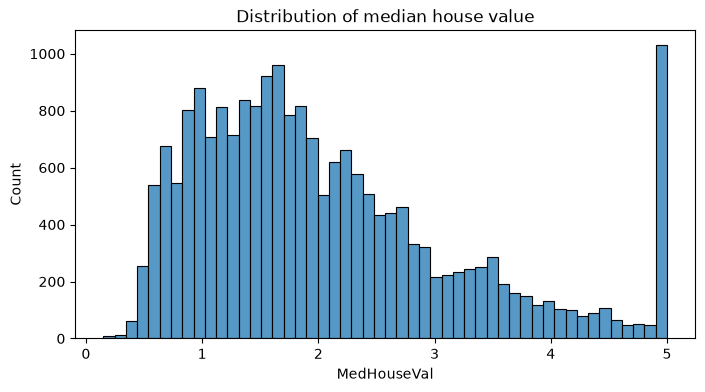

In [8]:
plt.figure(figsize=(8, 4))
sns.histplot(df["MedHouseVal"], bins=50)
plt.title("Distribution of median house value")
plt.show()

In [9]:
(df["MedHouseVal"] >= 5).sum()

np.int64(992)

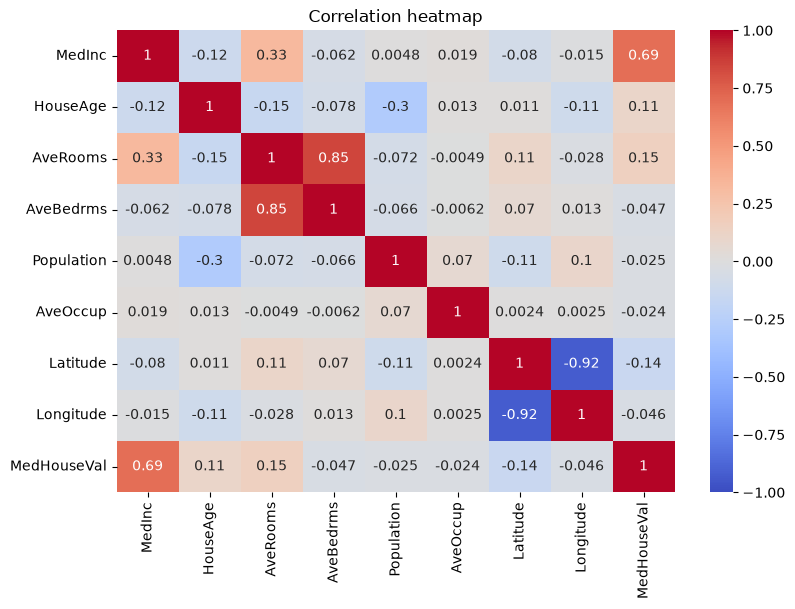

In [10]:
plt.figure(figsize=(9, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation heatmap")
plt.show()

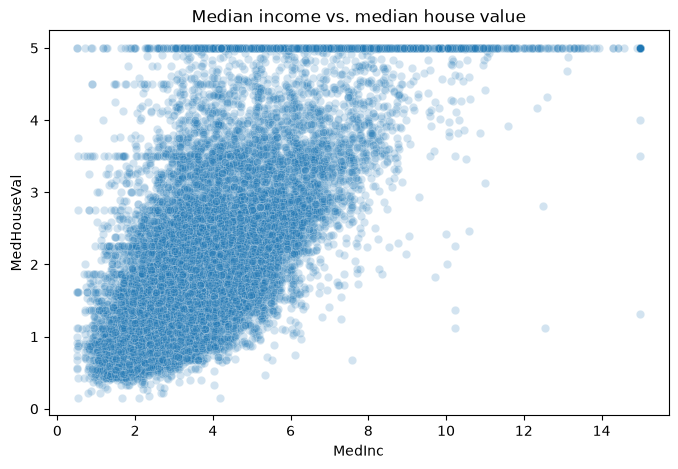

In [11]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="MedInc", y="MedHouseVal", alpha=0.2)
plt.title("Median income vs. median house value")
plt.show()

## EDA Summary

### 1. Dataset overview
- Source: "fetch_california_housing" by using "from sklearn.datasets import fetch_california_housing" code. Data comes from 1990 census.
- 20640 rows of neighborhoods, 9 columns (MedInc, HouseAge, AveRooms, AveBedrms, Population, AveOccup, Latitude, Longitude, MedHouseVal).
- Target = MedHouseVal = Neighborhood's median house value.
- Problem Type = Regression

### 2. Data quality
- Missing values: None, all columns state "20640 non-null" under Non-Null Count.
- Median Home Value values do not exceed $500,000 (5) as there were 992 rows that hit the cap. This creates an inaccuracy in our model as it can't learn true prices above 5.0.
- No duplicate rows verified with df.duplicated().sum() 
- All data types are "float64".
- Odd values are present. Determined by using "df.describe()" and seeing the "max" values of "AveRooms" and "AveOccup" being 141.9 and 1243.3, respectively. For reference, the mean is 5.4 for "AveRooms" and 3.1 for "AveOccup". For reference, the median is 5.2 for "AveRooms" and 2.8 for "AveOccup".

### 3. Target Analysis
- Distribution shape: right-skewed 
- With 992 capped rows, it accounts for about 5% of the data. 
- The values are in units of $100,000. 

### 4. Feature Analysis
- Columns of "AveRooms", "AveOccup", and "MedHouseVal" were focused on where these exhibited outliers worth noting. 
- After creating a correlation heatmap, MedInc (0.69), then AveRooms (0.15), Latitude (-0.14), and HouseAge (0.11), and everything else is below 0.05 in size.
- The weakest correlations are "AveOccup" at -0.024 and "Population" at -0.025. 
- A surprise is that "AveBedrms" had a relatively low correlation where in real life, that variable is a strong variable on choosing a house. 
- While "Latitude" had a correlation of -0.14 and "Longitude" had a correlation of "-0.046". Latitude and longitude show weak linear correlations, but location likely matters in a non-linear way (coastal vs. inland). A correlation number can't capture this, so next steps would be to plot the coordinates directly.
- Two patterns between features that should be noted are AveRooms and AveBedrms: 0.85 & Latitude and Longitude: -0.92.

### 5. Limitations
- Missing variables of square footage, school quality, and crime.
- Data is from 1990 with neighborhood-level data, not individual houses. 
- In addition to variables of the specific house, a good comparison and benchmark to compare our estimates to are the comparable sales in the area. Making sure there is that apples to apples comparison. 

### 6. Next Steps
- Next steps include plotting latitude vs. longitude, deciding plan of action for outliers and capped rows, and plotting AveRooms vs. AveBedrms to check for outliers. 

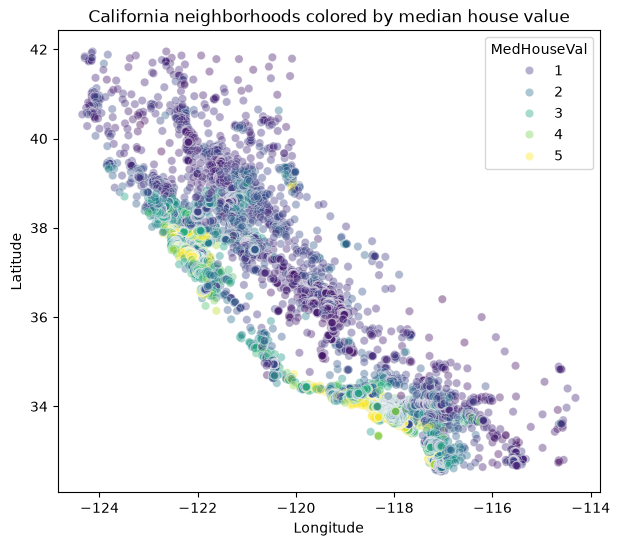

In [14]:
plt.figure(figsize=(7, 6))
sns.scatterplot(data=df, x="Longitude", y="Latitude", hue="MedHouseVal", alpha=0.4, palette="viridis")
plt.title("California neighborhoods colored by median house value")
plt.show()